# Proposal testing — label check

Goal: settle the label before finalizing the proposal.

1. Is `User score` usable? (Expectation: almost all zeros.)
2. What does `Estimated owners` look like, and what "hit" threshold gives a sensible class split?
3. Does release year confound the label? (Recent games haven't had time to sell.)

**Setup:** download `games.csv` from
[Kaggle — Steam Games Dataset (fronkongames)](https://www.kaggle.com/datasets/fronkongames/steam-games-dataset)
and put it in `data/` next to this notebook.

In [1]:
import csv
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

CSV_PATH = Path("data/games.csv")
assert CSV_PATH.exists(), f"Put the Kaggle CSV at {CSV_PATH.resolve()}"

## 1. Load, checking header alignment

Some versions of this CSV have one fewer header name than data fields (`Discount` and `DLC count`
fused into `DiscountDLC count`). pandas then silently uses `AppID` as the index and every column
after it is shifted by one. Compare the header against the first data row before trusting anything.

In [2]:
with open(CSV_PATH, encoding="utf-8", newline="") as f:
    reader = csv.reader(f)
    header = next(reader)
    first_row = next(reader)

print(f"header fields: {len(header)}   first-row fields: {len(first_row)}")

if len(first_row) == len(header):
    df = pd.read_csv(CSV_PATH)
elif len(first_row) == len(header) + 1 and "DiscountDLC count" in header:
    i = header.index("DiscountDLC count")
    header[i:i + 1] = ["Discount", "DLC count"]
    df = pd.read_csv(CSV_PATH, names=header, skiprows=1)
    print("Fixed fused 'DiscountDLC count' header.")
else:
    raise ValueError("Header/data field counts differ in an unexpected way — inspect manually:\n"
                     + "\n".join(f"{h!r:35} {v[:40]!r}" for h, v in zip(header, first_row)))

print(df.shape)
df.head(3)

header fields: 39   first-row fields: 40
Fixed fused 'DiscountDLC count' header.
(125855, 40)


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN


In [3]:
# Spot-check: each column name should match the kind of value under it
# (AppID = integer, Name = title, Release date = date, Estimated owners = "a - b" range, ...).
df.iloc[0]

AppID                                                                   2539430
Name                                                 Black Dragon Mage Playtest
Release date                                                        Aug 1, 2023
Estimated owners                                                          0 - 0
Peak CCU                                                                      0
Required age                                                                  0
Price                                                                       0.0
Discount                                                                      0
DLC count                                                                     0
About the game                                                              NaN
Supported languages                                                          []
Full audio languages                                                         []
Reviews                                 

## 2. Overview — dtypes, missingness, duplicates

In [4]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "null_%": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
})
overview.sort_values("null_%", ascending=False)

,dtype,null_%,n_unique
Score rank,float64,100.0,3
Movies,float64,100.0,0
Metacritic url,str,96.6,4162
Reviews,str,90.3,11987
Notes,str,81.5,19332
Website,str,59.9,40353
Support url,str,56.1,36161
Tags,str,33.8,77184
Support email,str,18.0,62321
Publishers,str,7.1,64607


In [5]:
print("duplicate rows:         ", df.duplicated().sum())
print("duplicate AppIDs:       ", df["AppID"].duplicated().sum())
print("duplicate Names:        ", df["Name"].duplicated().sum())

duplicate rows:          0
duplicate AppIDs:        0
duplicate Names:         1210


## 3. Is `User score` usable as a label?

In [6]:
for col in ["User score", "Metacritic score"]:
    zero_pct = (df[col] == 0).mean() * 100
    print(f"{col:18} zero: {zero_pct:5.1f}%   non-zero rows: {(df[col] != 0).sum():,}")

df["User score"].value_counts().head(10)

User score         zero: 100.0%   non-zero rows: 40
Metacritic score   zero:  96.6%   non-zero rows: 4,258


User score
0      125815
100         5
51          2
80          2
77          2
84          2
46          2
68          2
76          1
96          1
Name: count, dtype: int64

## 4. `Estimated owners` distribution

It's a range string like `"20000 - 50000"`. Parse out the lower bound and use that for thresholds.

In [7]:
bounds = df["Estimated owners"].astype(str).str.extract(r"(\d+)\s*-\s*(\d+)").astype(float)
df["owners_low"], df["owners_high"] = bounds[0], bounds[1]
print("unparsed rows:", df["owners_low"].isna().sum())

buckets = (df.groupby(["owners_low", "owners_high"]).size()
             .rename("games").reset_index()
             .sort_values("owners_low"))
buckets["pct"] = (buckets["games"] / len(df) * 100).round(2)
buckets["pct_at_or_above"] = buckets["pct"][::-1].cumsum()[::-1].round(2)
buckets

unparsed rows: 0


,owners_low,owners_high,games,pct,pct_at_or_above
0,0.0,0.0,24579,19.53,99.99
1,0.0,20000.0,75705,60.15,80.46
2,20000.0,50000.0,11397,9.06,20.31
3,50000.0,100000.0,5355,4.25,11.25
4,100000.0,200000.0,3454,2.74,7.00
5,200000.0,500000.0,2856,2.27,4.26
6,500000.0,1000000.0,1155,0.92,1.99
7,1000000.0,2000000.0,729,0.58,1.07
8,2000000.0,5000000.0,405,0.32,0.49
9,5000000.0,10000000.0,125,0.10,0.17


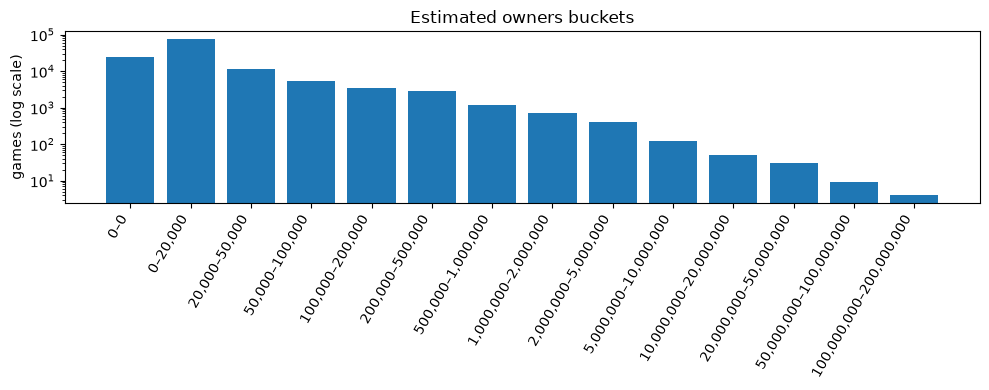

In [8]:
labels = [f"{int(lo):,}–{int(hi):,}" for lo, hi in zip(buckets["owners_low"], buckets["owners_high"])]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(labels, buckets["games"])
ax.set_yscale("log")
ax.set_ylabel("games (log scale)")
ax.set_title("Estimated owners buckets")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()

## 5. Threshold explorer — class split for each candidate "hit" definition

`0 - 0` usually means unreleased or no SteamSpy data — shown both with and without those rows.

In [9]:
zero_zero = (df["owners_low"] == 0) & (df["owners_high"] == 0)
print(f"'0 - 0' rows: {zero_zero.sum():,} ({zero_zero.mean():.1%})")

rows = []
for t in [50_000, 100_000, 200_000, 500_000, 1_000_000]:
    hit_all = df["owners_low"] >= t
    hit_nz = hit_all[~zero_zero]
    rows.append({"hit if owners >=": f"{t:,}",
                 "hits": int(hit_all.sum()),
                 "hit % (all rows)": round(hit_all.mean() * 100, 2),
                 "hit % (excl. 0-0)": round(hit_nz.mean() * 100, 2)})
pd.DataFrame(rows)

'0 - 0' rows: 24,579 (19.5%)


,hit if owners >=,hits,hit % (all rows),hit % (excl. 0-0)
0,"50,000",14174,11.26,14.00
1,"100,000",8819,7.01,8.71
2,"200,000",5365,4.26,5.30
3,"500,000",2509,1.99,2.48
4,"1,000,000",1354,1.08,1.34


## 6. Release-year confound

A game released last month sits in the lowest owners bucket no matter how good it is. If the hit
rate collapses for recent years, restrict to games released before some cutoff.

unparsed release dates: 0


,games,hit_pct
year,,
2017,5922,12.17
2018,7461,8.42
2019,7243,8.10
2020,8804,8.61
2021,11067,6.73
2022,12288,4.84
2023,14598,4.30
2024,20033,3.14
2025,24973,1.01


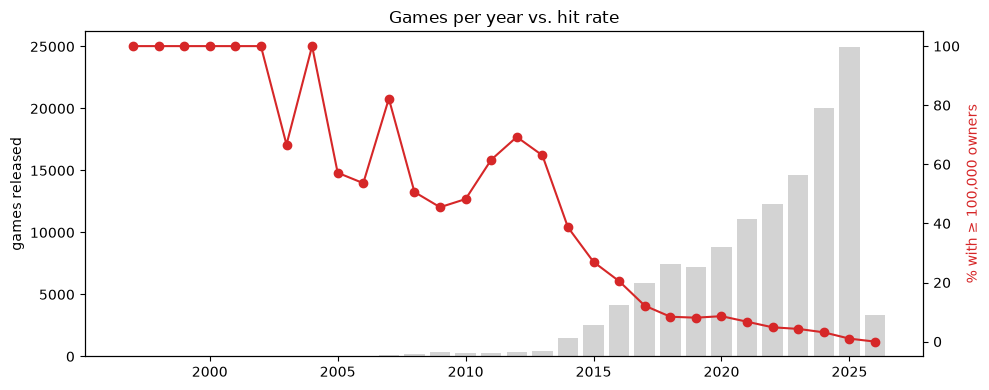

In [10]:
THRESHOLD = 100_000   # change to the threshold you're leaning toward

df["release_dt"] = pd.to_datetime(df["Release date"], format="mixed", errors="coerce")
print("unparsed release dates:", df["release_dt"].isna().sum())

by_year = (df.assign(year=df["release_dt"].dt.year, hit=df["owners_low"] >= THRESHOLD)
             .groupby("year").agg(games=("hit", "size"), hit_pct=("hit", "mean")))
by_year["hit_pct"] = (by_year["hit_pct"] * 100).round(2)

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(by_year.index, by_year["games"], color="lightgray", label="games released")
ax1.set_ylabel("games released")
ax2 = ax1.twinx()
ax2.plot(by_year.index, by_year["hit_pct"], marker="o", color="tab:red")
ax2.set_ylabel(f"% with ≥ {THRESHOLD:,} owners", color="tab:red")
ax1.set_title("Games per year vs. hit rate")
plt.tight_layout()
by_year.tail(10)

## Takeaways (fill in)

- `User score` usable? —
- Chosen threshold and resulting split —
- Row filters (drop `0 - 0`? release-date cutoff?) —
- Anything surprising for the EDA section —